# 01 - Power analysis and baseline test

**Scenario**: an e-commerce platform tests a streamlined checkout flow (treatment) against the existing flow (control). The primary success metric is checkout conversion rate, with a baseline of 3.5% and a minimum detectable effect (MDE) of a +8% relative lift.

This notebook answers two questions:
1. **How many users do we need?** Power analysis for a two-proportion z-test.
2. **What does one experiment look like?** Simulate at the recommended sample size and run the baseline significance test.

In [1]:
import sys
sys.path.insert(0, "..")  # so config, src and data import from the repo root

import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportions_ztest

import config
from data.generate_data import generate_experiment_data
from src.power import achieved_power, required_sample_size_per_arm
from src.plots import plot_power_curves

## 1. Required sample size

The standard two-proportion formula (Fleiss et al. 2003), with a two-sided alpha of 0.05 and 80% power. Smaller effects need dramatically more users: halving the MDE roughly quadruples the required sample size.

In [2]:
n_recommended = required_sample_size_per_arm(
    config.CONTROL_CONVERSION_RATE, config.MDE_RELATIVE
)
print(f"Baseline conversion: {config.CONTROL_CONVERSION_RATE:.1%}")
print(f"MDE: +{config.MDE_RELATIVE:.0%} relative "
      f"(to {config.CONTROL_CONVERSION_RATE * (1 + config.MDE_RELATIVE):.3%})")
print(f"Required sample size: {n_recommended:,} per arm "
      f"({2 * n_recommended:,} total)")
print(f"Runtime at {config.USERS_PER_DAY:,} users/day: "
      f"{2 * n_recommended / config.USERS_PER_DAY:.0f} days")

pd.DataFrame({
    "relative MDE": [f"+{m:.0%}" for m in (0.04, 0.06, 0.08, 0.10, 0.12)],
    "n per arm": [
        required_sample_size_per_arm(config.CONTROL_CONVERSION_RATE, m)
        for m in (0.04, 0.06, 0.08, 0.10, 0.12)
    ],
})

Baseline conversion: 3.5%
MDE: +8% relative (to 3.780%)
Required sample size: 70,229 per arm (140,458 total)
Runtime at 10,000 users/day: 14 days


,relative MDE,n per arm
0,+4%,275715
1,+6%,123696
2,+8%,70229
3,+10%,45362
4,+12%,31790


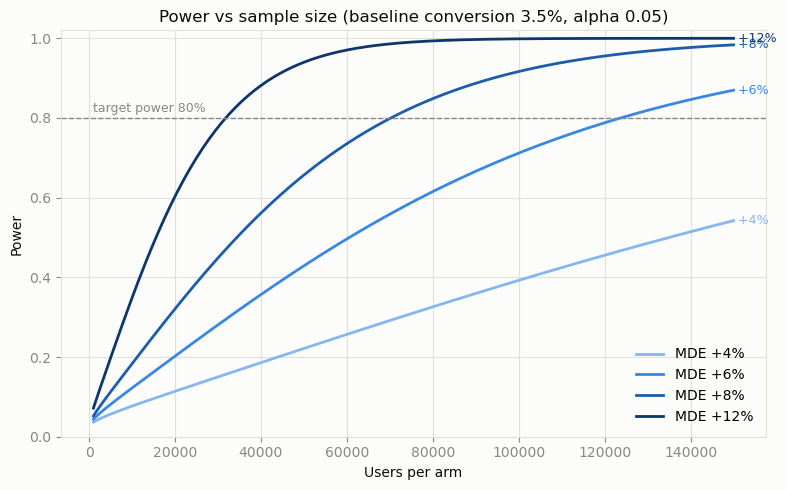

In [3]:
fig = plot_power_curves(
    baseline_rate=config.CONTROL_CONVERSION_RATE,
    mde_relative_list=[0.04, 0.06, 0.08, 0.12],
    n_max_per_arm=150_000,
)

## 2. Baseline test on one simulated experiment

We simulate one experiment at the recommended sample size. The generator injects the true +8% relative lift, so a well-powered test should usually (80% of the time) detect it. The test is the standard two-proportion z-test; the confidence interval for the rate difference uses the unpooled (Wald) standard error.

In [4]:
df = generate_experiment_data(n_users=2 * n_recommended, seed=config.RANDOM_SEED)

control = df[df["group"] == "control"]["converted"]
treatment = df[df["group"] == "treatment"]["converted"]
p_c, p_t = control.mean(), treatment.mean()
diff = p_t - p_c

z_stat, p_value = proportions_ztest(
    [treatment.sum(), control.sum()], [len(treatment), len(control)]
)

# 95% CI for the difference in rates, unpooled (Wald) standard error.
from scipy.stats import norm
se_diff = np.sqrt(p_c * (1 - p_c) / len(control) + p_t * (1 - p_t) / len(treatment))
z_crit = norm.ppf(1 - config.ALPHA / 2)
ci_low, ci_high = diff - z_crit * se_diff, diff + z_crit * se_diff

print(f"Control conversion:   {p_c:.4%}  (n = {len(control):,})")
print(f"Treatment conversion: {p_t:.4%}  (n = {len(treatment):,})")
print(f"Absolute lift:        {diff:+.4%}  "
      f"(95% CI [{ci_low:+.4%}, {ci_high:+.4%}])")
print(f"Relative lift:        {diff / p_c:+.2%}")
print(f"z = {z_stat:.3f}, p-value = {p_value:.4f} "
      f"({'significant' if p_value < config.ALPHA else 'not significant'} "
      f"at alpha = {config.ALPHA})")

Control conversion:   3.5427%  (n = 70,229)
Treatment conversion: 3.8588%  (n = 70,229)
Absolute lift:        +0.3161%  (95% CI [+0.1187%, +0.5136%])
Relative lift:        +8.92%
z = 3.138, p-value = 0.0017 (significant at alpha = 0.05)


## Takeaways

- Detecting a +8% relative lift on a 3.5% baseline needs roughly 70k users per arm. Rare binary metrics are expensive to test; this motivates the variance reduction work (CUPED) in notebook 02.
- The single simulated experiment above is one draw: with 80% power, about 1 in 5 identically-run experiments would miss this real effect. The validation script `validate_phase1.py` confirms the 80% detection rate over 1,000 simulations.
- The A/A behavior (false positive rate ~5% when the true lift is zero) is also verified there.